# 4U 1624−49: observational processing and joint Stokes spectroscopy

We document our adopted **standard-v4-20261007** data selection and display the
**2026-10-14 low- and high-reflection reference fits**. This notebook complements
`paper_companion.ipynb`; it does not replace the theoretical calculations.

**Run All is offline and read-only with respect to the observations.** We load
bundled exports, verify their checksums, and plot existing products. We do not
download observations, rerun extraction, load XSPEC, optimize parameters, run
chains, or regenerate models. The fit section displays only the adopted best-fit
parameters and cached predictions. Missing files cause an error, never a refit.

This is a documented processing record and cached-results demonstration, **not
a self-contained raw-telemetry-to-fit pipeline**. Event lists, L1 files, response
matrices, calibration databases and external model tables are not bundled here.
The small image/channel exports retain their source filenames and hashes.

## 1. Load and verify the portable data

In [1]:
from pathlib import Path
import json, hashlib, html
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle
from IPython.display import display, Markdown, HTML
from plot_style import apply_mnras_style, get_double_column_size
from helpers.western import load_verified_fits
apply_mnras_style()
ROOT = Path.cwd()
DATA = ROOT / 'data/observations'
def read(name): return json.loads((DATA/name).read_text())
audit = read('export_audit.json')
assert audit['refitted'] is False and audit['reextracted'] is False
for name, digest in audit['files_sha256'].items():
    assert hashlib.sha256((DATA/name).read_bytes()).hexdigest() == digest, name
selection = read('selection.json')
spectra = read('ungrouped_spectra.json')
bindings = read('data-bindings.json')['spectra']
fits = load_verified_fits()
labels = {1:'NuSTAR FPMA', 2:'NuSTAR FPMB', 3:'NICER',
          4:'IXPE DU1', 5:'IXPE DU2', 6:'IXPE DU3',
          7:'IXPE DU1', 8:'IXPE DU1', 9:'IXPE DU2', 10:'IXPE DU2',
          11:'IXPE DU3', 12:'IXPE DU3'}
def table(headers, rows):
    display(HTML('<table><thead><tr>'+''.join('<th>'+html.escape(str(a))+'</th>' for a in headers)+
                 '</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(a))+'</td>' for a in row)+'</tr>' for row in rows)+'</tbody></table>'))
print('Verified observational exports and both cached joint fits. No fit executed.')

Verified observational exports and both cached joint fits. No fit executed.


## 2. Observations and calibration provenance

We use IXPE ObsID **02007301**, NuSTAR ObsID **90901327002**, and NICER
ObsIDs **6203930102–6203930105**. The last digit is part of each observation ID,
not a detector identifier. NICER 6203930102 has no exposure left after our
joint non-dip selection and is not included in the combined spectrum.

We retain archived IXPE SOC L2 v02 event calibration (CALDBVER 20221020),
NuSTAR cleaned-event CALDBVER 20240130, and NICER xti20240206.
Responses were selected using historical IXPE 20240125, NuSTAR 20240130,
and NICER 20240206 calibration indices. Event calibration and response
calibration are different records; we do not claim a new L1 reconstruction.

Recorded tools include nuproducts 0.3.5, nicerl3-spect 1.14, and XSPEC 12.15.1.
The standard extraction used **HEASoft ixpeproduct**, not an ixpeobssim PCUBE
as the fitted spectrum. ixpeobssim 33.2.1 was used for a separate cross-check.
The table below reports spectral exposures, not GTI ontime.

In [2]:
table(['Instrument', 'Source spectrum', 'Exposure (s)', 'Start', 'End'],
      [[labels[s['group']], Path(s['source']['file']).name, f"{s['source']['exposure']:.3f}",
        s['source']['date_obs'], s['source']['date_end']] for s in spectra[:6]])
# Full source/background/response identifiers and SHA256 hashes are accessible here.
display(HTML('<details><summary>All spectrum and response bindings</summary><pre>'+html.escape(json.dumps(bindings,indent=2))+'</pre></details>'))

Instrument,Source spectrum,Exposure (s),Start,End
NuSTAR FPMA,nu90901327002A01_sr.pha,30828.912,2023-08-20T18:54:37.1840,2023-08-21T16:39:20.1840
NuSTAR FPMB,nu90901327002B01_sr.pha,30442.752,2023-08-20T18:54:37.1840,2023-08-21T16:39:20.1840
NICER,combined.pha,2214.000,None,None
IXPE DU1,ixpe02007301_DU1_I.pi,189236.497,2023-08-19T09:51:25.1840,2023-08-23T08:55:31.1840
IXPE DU2,ixpe02007301_DU2_I.pi,189314.553,2023-08-19T09:51:25.1840,2023-08-23T08:55:31.1840
IXPE DU3,ixpe02007301_DU3_I.pi,189189.270,2023-08-19T09:51:25.1840,2023-08-23T08:55:31.1840


## 3. Sky images and source/background regions

We show **full-observation calibrated event images before the non-dip time cut**,
not raw telemetry. IXPE has already undergone the historical particle rejection.
Green circles mark the source; orange circles mark the background.
The common source centre is RA = 247.01177083°, Dec = −49.19850278° (FK5).
We use a 120″ source radius. IXPE uses a 180–240″ background annulus;
NuSTAR uses separate 60″ background circles in each focal-plane module.
NICER is non-imaging: it has no analogous source/background sky aperture,
and we use the SCORPEON v23 background model.

The plots use sky-image pixel offsets converted to arcseconds (east is left).
For display only, events are histogrammed on a 4″ grid; this is unrelated to
spectral grouping. IXPE is shown in 2–8 keV and NuSTAR with PI 35–485.

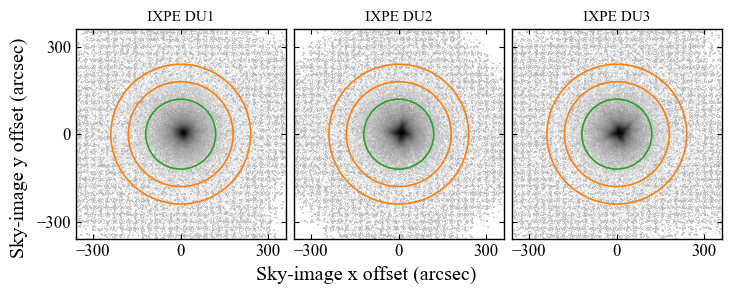

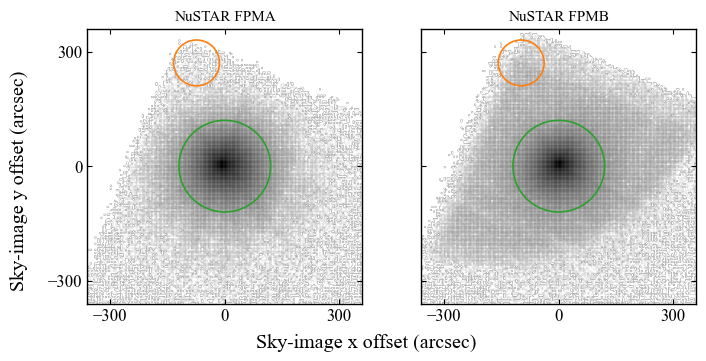

Instrument,Region,Recorded DS9 definition
IXPE DU1,source,"fk5 circle(247.01177083,-49.19850278,120"")"
IXPE DU1,background,"fk5 annulus(247.01177083,-49.19850278,180"",240"")"
IXPE DU2,source,"fk5 circle(247.01177083,-49.19850278,120"")"
IXPE DU2,background,"fk5 annulus(247.01177083,-49.19850278,180"",240"")"
IXPE DU3,source,"fk5 circle(247.01177083,-49.19850278,120"")"
IXPE DU3,background,"fk5 annulus(247.01177083,-49.19850278,180"",240"")"
NuSTAR FPMA,source,"fk5 circle(247.01177083,-49.19850278,120"")"
NuSTAR FPMA,background,"fk5 circle(247.043088741,-49.123392841,60"")"
NuSTAR FPMB,source,"fk5 circle(247.01177083,-49.19850278,120"")"
NuSTAR FPMB,background,"fk5 circle(247.053522316,-49.123390570,60"")"


In [3]:
image_meta = read('event_images.json')
images = np.load(DATA/'event_images.npz')
for subset in [image_meta[:3],image_meta[3:]]:
    fig, axs = plt.subplots(1,len(subset),figsize=(7.2,2.8 if len(subset)==3 else 3.5),sharex=True,sharey=True,layout='constrained')
    for ax, meta in zip(axs,subset):
        im=images[meta['key']]
        ax.imshow(im,origin='lower',extent=meta['extent'],norm=LogNorm(vmin=1,vmax=max(2,im.max())),cmap='gray_r')
        for region in meta['regions']:
            for radius in region['radii_arcsec']:
                ax.add_patch(Circle(region['center_arcsec'],radius,fill=False,lw=1.2,
                                    color='C2' if region['role']=='source' else 'C1'))
        ax.set_title(meta['label'],fontsize=11)
        ax.set_xticks([-300,0,300]); ax.set_yticks([-300,0,300])
    fig.supxlabel('Sky-image x offset (arcsec)');fig.supylabel('Sky-image y offset (arcsec)')
    plt.show()
table(['Instrument','Region','Recorded DS9 definition'],
      [[m['label'],r['role'],r['text'].strip()] for m in image_meta for r in m['regions']])

### 3.1 Historical particle rejection

We retained the historical event rejection before extracting Stokes spectra.
The recorded implementation matches L1/L2 events in TIME and retains events satisfying

\[
0.8[1-\exp(-(E+0.25)/1.1)]+0.004E < {\tt EVT\_FRA}<1,
\quad {\tt NUM\_PIX}<130+30(E-2),\quad {\tt TRK\_BORD}<2,
\]

where the implementation uses $E=0.04\,{\tt PI}$ in keV. The original L2 column/WCS
metadata were restored using retained TRG_IDs after the historical writer.
Consequently `backrej=no` in the later ixpeproduct command means **do not apply
the rejection twice**, not that no particle rejection was used.

## 4. Non-dip time selection and exposure accounting

We construct 16 s bins from ordinary, unweighted source-region 2–8 keV events
after particle rejection. The plotted rate is
$r=N_{\rm DU1+DU2+DU3}/(T_{\rm DU1}+T_{\rm DU2}+T_{\rm DU3})$.
We require summed DU livetime ≥9.6 s and select $r>0.45$ count s$^{-1}$ per DU.
This is **not** a weighted NEFF light curve and is not the unnormalised
three-DU summed rate. Unknown bins and gaps are not interpolated.

Our per-DU interpretation resolves an ambiguity between the literature figure
and prose; **these are our independently constructed GTIs, not author-supplied
GTIs**. We intersect the master selection with each mission's GTIs after
converting the mission time origins. This conservative choice discards other
mission exposure when IXPE has no state information.

For IXPE, the selected exposure uses the original full-observation
LIVETIME/ONTIME ratio, an approximate constant deadtime correction (<0.2%).
NuSTAR's spectral exposure additionally includes its own deadtime treatment.
GTI ontime and spectral exposure must therefore not be interchanged.

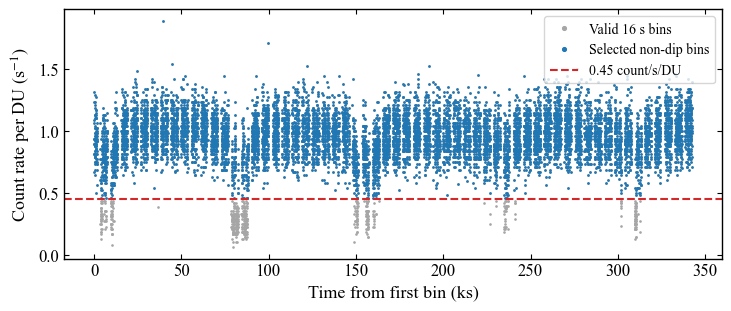

IXPE mission-time origin (s): 209209816.0
Timing reference: {'MJDREFI': 57754, 'MJDREFF': 0.00080074074074, 'TIMESYS': 'TT', 'TIMEZERO': 0.0}


Event file,Own GTI (s),Non-dip (s),Dip (s),Unknown (s)
ixpe02007301_det2_evt2_v02_rej.fits,199352.132,189677.488,9574.0,100.644
ixpe02007301_det1_evt2_v02_rej.fits,199281.109,189609.042,9573.556,98.51
ixpe02007301_det3_evt2_v02_rej.fits,199240.321,189553.776,9569.748,116.798
nu90901327002B01_cl.evt,47683.676,35879.476,902.0,10902.2
nu90901327002A01_cl.evt,47670.676,35869.476,899.0,10902.2
ni6203930104_0mpu7_cl.evt,803.0,223.0,0.0,580.0
ni6203930102_0mpu7_cl.evt,147.0,0.0,0.0,147.0
ni6203930105_0mpu7_cl.evt,696.0,595.0,16.0,85.0
ni6203930103_0mpu7_cl.evt,1792.0,1396.0,5.0,391.0


In [4]:
lc=np.load(DATA/'lightcurve.npz')
time=(lc['edges'][:-1]+lc['edges'][1:])/2
origin=lc['edges'][0]; x=(time-origin)/1000
valid=lc['valid'].astype(bool); rate=lc['rate_per_DU']; selected=valid&(rate>0.45)
fig,ax=plt.subplots(figsize=get_double_column_size(),layout='constrained')
ax.plot(x[valid],rate[valid],'.',ms=1.8,color='0.65',label='Valid 16 s bins')
ax.plot(x[selected],rate[selected],'.',ms=1.8,color='C0',label='Selected non-dip bins')
ax.axhline(.45,color='C3',ls='--',label='0.45 count/s/DU')
ax.set(xlabel='Time from first bin (ks)',ylabel='Count rate per DU (s$^{-1}$)')
ax.legend(loc='upper right',markerscale=3,fontsize=10);plt.show()
print('IXPE mission-time origin (s):',origin)
print('Timing reference:',read('gti.json')['nondip']['header'])
table(['Event file','Own GTI (s)','Non-dip (s)','Dip (s)','Unknown (s)'],
      [[Path(r['event']).name,round(r['own_GTI_ontime_s'],3),
        *[round(r['selected_ontime_s'][k],3) for k in ['nondip','dip','unknown']]]
       for r in selection['mission_exposure_partition']])
assert selected.sum()==selection['summary']['nondip_per_DU']['bins']

## 5. Extraction, response handling and grouping

We record the actual command arguments below without executing them.
`${OBS_ROOT}` is a portable placeholder for the original observation tree,
not a path needed to run this notebook. The complete GTIs are in `data/observations/gti.json`.

- IXPE: ixpeproduct `weight=1`, `backrej=no`, `binlc=16`; separate I/Q/U source and background products and each DU's response.
- NuSTAR: nuproducts with each module's region files and converted GTI; `pilow=35`, `pihigh=485`, `binsize=120`.
- NICER: nicerl3-spect with SCORPEON v23, file background; ftaddspec `sumtype=TIME` combines the selected observations and their responses/backgrounds.
- NuSTAR and NICER: ftgrouppha `grouptype=optmin`, `groupscale=25`.
- IXPE: I is grouped with `grouptype=min`, `groupscale=25`; the matching DU's I GROUPING and QUALITY columns are copied to Q and U. **Signed Q/U values are never treated as grouping counts.**

The exported raw channels below ignore the GROUPING column for display only.
The later fit figures use the original fit grouping without further display rebinning.

In [5]:
commands=read('commands.json')
for name, command in commands.items():
    if name.startswith('cross-validation/'): continue
    display(HTML('<details><summary>'+html.escape(name)+'</summary><pre>'+html.escape(' '.join(command))+'</pre></details>'))
table(['Group','Instrument','Stokes','Raw channels','Source exposure','Background exposure','Background rate scale'],
      [[s['group'],labels[s['group']], 'I' if s['group']<=6 else ('Q' if s['group']%2 else 'U'),
        len(s['source']['channel']),round(s['source']['exposure'],3),round(s['background']['exposure'],3),
        s['background_rate_scale']] for s in spectra])

Group,Instrument,Stokes,Raw channels,Source exposure,Background exposure,Background rate scale
1,NuSTAR FPMA,I,4096,30828.912,30828.912,7.058872610522432
2,NuSTAR FPMB,I,4096,30442.752,30442.752,7.410111793346931
3,NICER,I,1501,2214.0,3000000000.0,1.0
4,IXPE DU1,I,375,189236.497,189236.497,0.571306434069586
5,IXPE DU2,I,375,189314.553,189314.553,0.571306434069586
6,IXPE DU3,I,375,189189.27,189189.27,0.571306434069586
7,IXPE DU1,Q,375,189236.497,189236.497,0.571306434069586
8,IXPE DU1,U,375,189236.497,189236.497,0.571306434069586
9,IXPE DU2,Q,375,189314.553,189314.553,0.571306434069586
10,IXPE DU2,U,375,189314.553,189314.553,0.571306434069586


## 6. Ungrouped extracted spectra

We plot each native extraction channel, without spectral rebinning. These are
response-folded rates, not unfolded photon spectra. For the independently
extracted source aperture and background, we use

\[
R_{\rm net}=R_{\rm src}-fR_{\rm bg},\qquad
\sigma_{\rm net}^2=\sigma_{\rm src}^2+f^2\sigma_{\rm bg}^2,
\quad f={\tt BACKSCAL}_{\rm src}/{\tt BACKSCAL}_{\rm bg}.
\]

Each rate already includes its own exposure division. We use supplied STAT_ERR
when present and Poisson count errors only for count spectra without STAT_ERR;
we never apply $\sqrt Q$ or $\sqrt U$. Plotted densities also divide by the
channel width. Linear axes retain negative background-subtracted values.
The dense appearance here is intentional. No extra systematic term is added
to these display exports; the cached fit residuals below are authoritative.

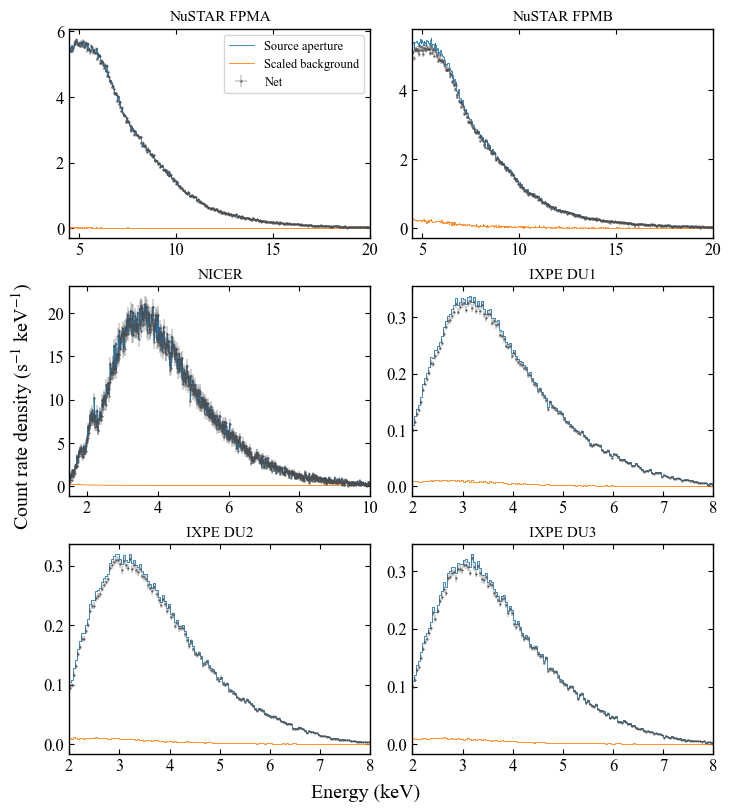

In [6]:
def raw_arrays(s):
    lo=np.array(s['elo']);hi=np.array(s['ehi']);width=hi-lo
    source=s['source'];bg=s['background'];f=s['background_rate_scale']
    a=np.array(source['rate']);b=f*np.array(bg['rate'])
    err=np.hypot(source['error'],f*np.array(bg['error']))
    return (lo+hi)/2,width/2,a/width,b/width,(a-b)/width,err/width
fig,axs=plt.subplots(3,2,figsize=(7.2,8.0),layout='constrained')
for ax,s in zip(axs.flat,spectra[:6]):
    e,de,a,b,net,err=raw_arrays(s);band=(4.5,20) if s['group']<3 else ((1.5,10) if s['group']==3 else (2,8))
    m=(e>=band[0])&(e<=band[1])
    ax.step(e[m],a[m],where='mid',lw=.6,label='Source aperture')
    ax.step(e[m],b[m],where='mid',lw=.6,label='Scaled background')
    ax.errorbar(e[m],net[m],xerr=de[m],yerr=err[m],fmt='.',ms=1,lw=.35,color='0.3',label='Net')
    ax.set_title(labels[s['group']],fontsize=11);ax.set_xlim(band)
axs[0,0].legend(fontsize=9)
fig.supxlabel('Energy (keV)');fig.supylabel('Count rate density (s$^{-1}$ keV$^{-1}$)');plt.show()

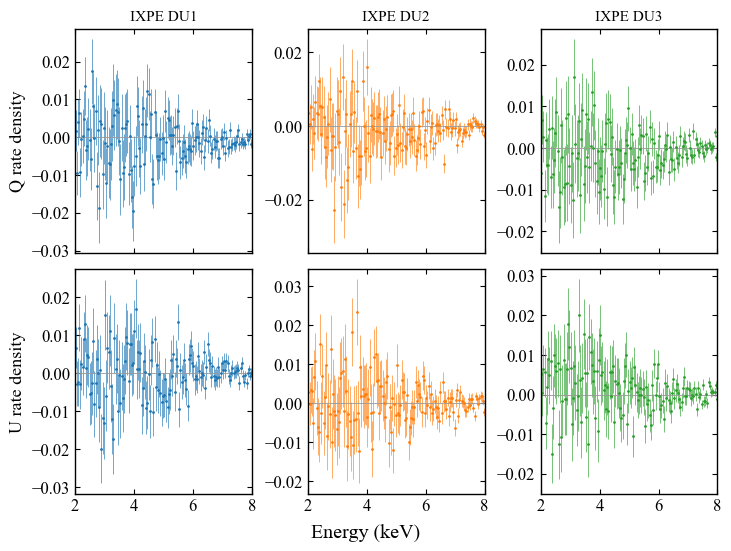

In [7]:
fig,axs=plt.subplots(2,3,figsize=(7.2,5.4),sharex=True,layout='constrained')
for row,stokes in enumerate('QU'):
    for col,du in enumerate([1,2,3]):
        s=spectra[6+2*col+row];e,de,a,b,net,err=raw_arrays(s);m=(e>=2)&(e<=8)
        ax=axs[row,col]
        ax.errorbar(e[m],net[m],xerr=de[m],yerr=err[m],fmt='.',ms=2,lw=.45,color=f'C{col}')
        ax.axhline(0,color='0.6',lw=.6);ax.set_xlim(2,8)
        if row==0: ax.set_title(f'IXPE DU{du}',fontsize=11)
        if col==0: ax.set_ylabel(stokes+' rate density')
fig.supxlabel('Energy (keV)');plt.show()

## 7. Adopted joint-fit model and parameters — no refitting

We use the recursion + Jones model with a diskbb seed spectrum and jointly
fit I, Q and U, retaining all three IXPE DUs as distinct data groups.
Only the coronal component is polarized in this model. Q/U are in the sky
Stokes basis; the MCRT basis conversion is not applied to these observations.
The low-reflection model includes bbodyrad; the high-reflection model does not.
Absorption uses TBabs, an edge and our Cloudy C23.01 table; the reflection
component is relxillNS. Exact expressions, energy grids, frozen values, parameter
links and the saved gain settings are displayed below.

We restrict NuSTAR to 4.5–20 keV, NICER to 1.5–10 keV and IXPE to 2–8 keV.
These are the adopted reference solutions, not posterior medians or guaranteed
unique global minima. The high-branch inclination reaches the model boundary.
The separate profile intervals in the companion data are not MCMC posteriors.

**The following cell only displays saved values.** There is deliberately no
`Fit.perform`, optimizer, chain, executable XSPEC setup or fallback calculation.
Historical starting templates are not presented as updated best-fit snapshots.

In [8]:
table(['Branch','chi2','dof','kTe (keV)','tau','Inclination (deg)','PA (deg)'],
      [[branch, f"{d['result']['chi2']:.6f}",d['result']['dof'],
        *[d['point']['groups'][0][i-1]['values'][0] for i in [8,9,10,15]]]
       for branch,d in fits.items()])
for branch,d in fits.items():
    point=d['point']
    display(Markdown('### 7.'+('1' if branch=='low' else '2')+' '+branch.capitalize()+'-reflection best-fit parameters'))
    print(point['expression'])
    print('Numerical settings:',{k:point[k] for k in ['bins','cells','quad','energy_grid','fit_energy_keV']})
    table(['Index','Parameter (group 1)','Best value','Frozen','Link'],
          [[p['index'],p['name'],f"{p['values'][0]:.10g}",p['frozen'],p['link']] for p in point['groups'][0]])
    display(HTML('<details><summary>All 12 groups: bounds, links, calibration and gain values</summary><pre>'+html.escape(json.dumps({'groups':point['groups'],'gain':point['gain']},indent=2))+'</pre></details>'))

Branch,chi2,dof,kTe (keV),tau,Inclination (deg),PA (deg)
low,1569.879853,1572,2.6447083841260195,13.09683119758807,81.56716367598082,78.87390779256317
high,1567.583843,1573,2.6538756663400545,17.38740976479632,87.0,80.05746816739786


### 7.1 Low-reflection best-fit parameters

constant*TBabs*edge*mtable{source:cloudy23_western.fits}(slabseed:b05fac4f + bbodyrad + relxillNS)
Numerical settings: {'bins': 840, 'cells': 1024, 'quad': 36, 'energy_grid': '0.01 1 400 log 10 4500 lin 1000 1000 log', 'fit_energy_keV': {'NuSTAR': [4.5, 20.0], 'NICER': [1.5, 10.0], 'IXPE': [2.0, 8.0]}}


Index,Parameter (group 1),Best value,Frozen,Link
1,factor,1,True,
2,nH,10.04559304,False,
3,edgeE,1.839,True,
4,MaxTau,0.336728072,False,
5,logxi,3.82622246,False,
6,logNH,22.57271173,False,
7,z,0,True,
8,kTe,2.644708384,False,
9,tau,13.0968312,False,
10,incl,81.56716368,False,= p24


### 7.2 High-reflection best-fit parameters

constant*TBabs*edge*mtable{source:cloudy23_western.fits}(slabseed:b05fac4f + relxillNS)
Numerical settings: {'bins': 840, 'cells': 1024, 'quad': 36, 'energy_grid': '0.01 1 400 log 10 4500 lin 1000 1000 log', 'fit_energy_keV': {'NuSTAR': [4.5, 20.0], 'NICER': [1.5, 10.0], 'IXPE': [2.0, 8.0]}}


Index,Parameter (group 1),Best value,Frozen,Link
1,factor,1,True,
2,nH,9.417197882,False,
3,edgeE,1.839,True,
4,MaxTau,0.297156144,False,
5,logxi,3.890412685,False,
6,logNH,22.43397663,False,
7,z,0,True,
8,kTe,2.653875666,False,
9,tau,17.38740976,False,
10,incl,87,False,= p22


## 8. Joint-fit spectra and residuals, without display rebinning

We show the **native fit bins**, which are already grouped as described in
Section 5, not the ungrouped channels of Section 6. We apply no further rebinning.
The cached predictions are folded through each instrument/DU response.
Residuals are $(D-M)/\sigma$ with the same cached uncertainties used in the fit.
We retain every DU in the Q and U figures instead of merging their responses.

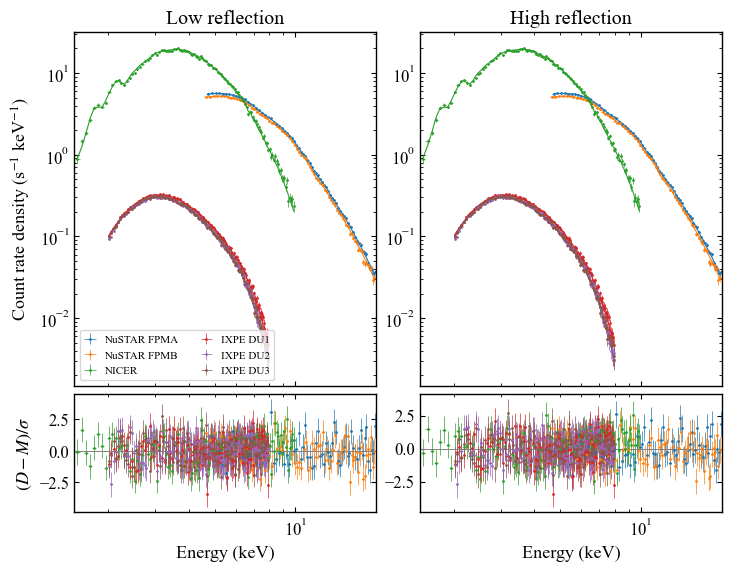

In [9]:
fig,axs=plt.subplots(2,2,figsize=(7.2,5.6),sharex='col',gridspec_kw={'height_ratios':[3,1]},layout='constrained')
for col,branch in enumerate(['low','high']):
    for r in fits[branch]['native']:
        if r['stokes']!='I':continue
        e=np.array(r['energy']);y=np.array(r['data']);err=np.array(r['error']);model=np.array(r['model']);color=f"C{r['group']-1}"
        axs[0,col].errorbar(e,y,xerr=r['halfwidth'],yerr=err,fmt='.',ms=2,lw=.5,color=color,label=labels[r['group']])
        axs[0,col].plot(e,model,lw=.8,color=color)
        axs[1,col].errorbar(e,r['residual_sigma'],xerr=r['halfwidth'],yerr=np.ones_like(e),fmt='.',ms=2,lw=.5,color=color)
    axs[0,col].set(xscale='log',yscale='log',title=branch.capitalize()+' reflection')
    axs[1,col].axhline(0,color='0.5',lw=.7)
    axs[1,col].set(xlabel='Energy (keV)',xlim=(1.5,20))
axs[0,0].set_ylabel('Count rate density (s$^{-1}$ keV$^{-1}$)')
axs[1,0].set_ylabel(r'$(D-M)/\sigma$')
axs[0,0].legend(fontsize=8,loc='lower left',ncol=2,handlelength=1)
plt.show()

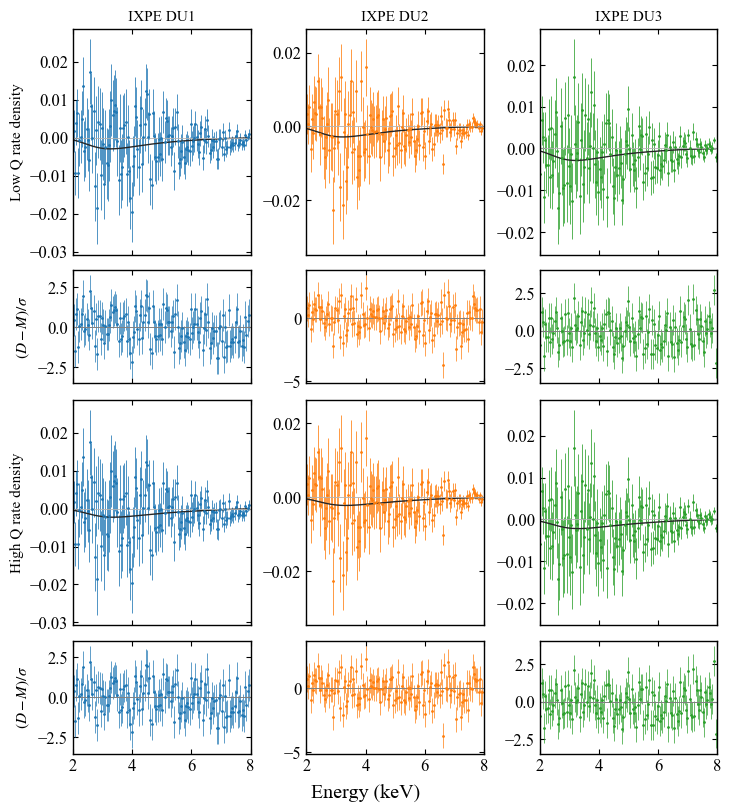

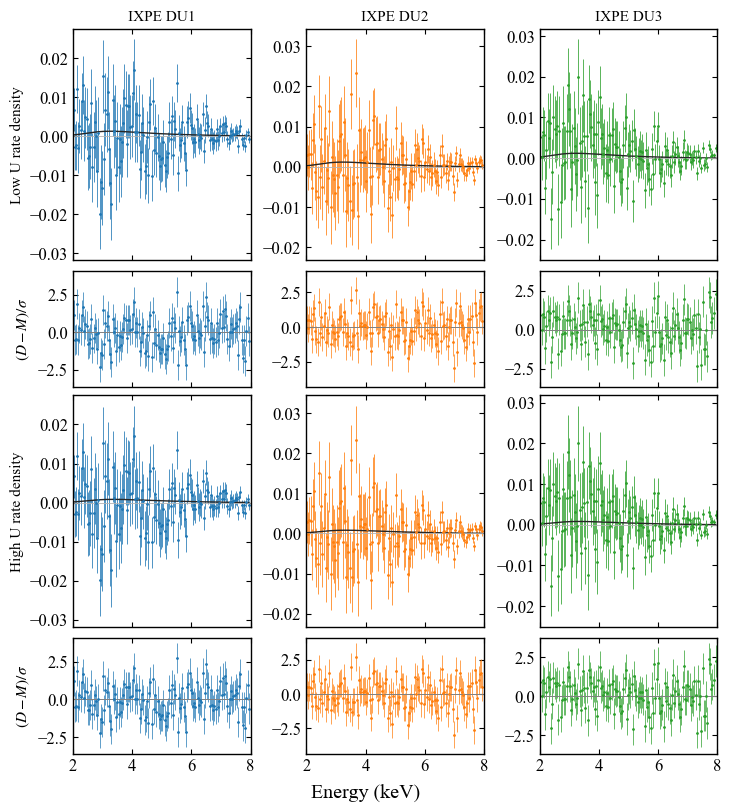

In [10]:
for stokes in 'QU':
    fig,axs=plt.subplots(4,3,figsize=(7.2,8.0),sharex=True,
                         gridspec_kw={'height_ratios':[2,1,2,1]},layout='constrained')
    for branch_index,branch in enumerate(['low','high']):
        rows=[r for r in fits[branch]['native'] if r['stokes']==stokes]
        for col,r in enumerate(rows):
            ax,res=axs[2*branch_index,col],axs[2*branch_index+1,col];e=np.array(r['energy'])
            ax.errorbar(e,r['data'],xerr=r['halfwidth'],yerr=r['error'],fmt='.',ms=2,lw=.55,color=f'C{col}')
            ax.plot(e,r['model'],color='0.15',lw=1)
            ax.axhline(0,color='0.7',lw=.6)
            res.errorbar(e,r['residual_sigma'],xerr=r['halfwidth'],yerr=np.ones_like(e),fmt='.',ms=2,lw=.5,color=f'C{col}')
            res.axhline(0,color='0.5',lw=.7);res.set_xlim(2,8)
            if branch_index==0:ax.set_title(f'IXPE DU{col+1}',fontsize=11)
            if col==0:
                ax.set_ylabel(branch.capitalize()+' '+stokes+' rate density',fontsize=11)
                res.set_ylabel(r'$(D-M)/\sigma$',fontsize=11)
    fig.supxlabel('Energy (keV)');plt.show()

## 9. Binning and combining the three DUs for display

### 9.1 Fit grouping versus display grouping

We distinguish three operations:

| Product | Grouping rule | Purpose |
| --- | --- | --- |
| NuSTAR/NICER I | ftgrouppha `optmin`, `groupscale=25`, instrument RMF | Native fitting bins |
| IXPE I | ftgrouppha `min`, `groupscale=25` | Native fitting bins |
| IXPE Q/U | Copy matching DU I GROUPING and QUALITY | Native fitting bins; never group on signed Q/U counts |
| IXPE I in the paper display | Per-DU `optmin`, `groupscale=25`, matching RMF | Coarser display only |
| IXPE Q/U in the paper display | Six common 1 keV bins from 2 to 8 keV | Display only; then sum three DU rate densities |

Optimal grouping is response-resolution-aware, not a fixed energy width.
We use the saved grouping/results rather than reimplementing the HEASoft
algorithm. We do not rerun ftgrouppha or change any fitted PHA file here.
The following table counts bins in the fitted energy band; raw channels are
counted by their centre, whereas cached fit/display bins use the original
XSPEC selection. Edge conventions can therefore differ slightly.

Instrument,Raw channels in band,Native fit bins,Paper-display I bins
NuSTAR FPMA,388,71,71
NuSTAR FPMB,388,74,74
NICER,850,113,113
IXPE DU1,150,149,15
IXPE DU2,150,149,15
IXPE DU3,150,148,15


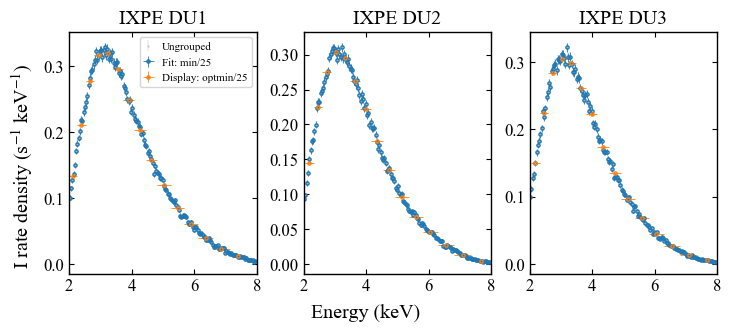

In [11]:
rows=[]
for s in spectra[:6]:
    g=s['group'];e=(np.array(s['elo'])+s['ehi'])/2
    band=(4.5,20) if g<3 else ((1.5,10) if g==3 else (2,8))
    native=next(r for r in fits['low']['native'] if r['group']==g)
    coarse=next(r for r in fits['low']['i_folded'] if r['group']==g)
    rows.append([labels[g],int(((e>=band[0])&(e<=band[1])).sum()),
                 len(native['data']),len(coarse['data'])])
table(['Instrument','Raw channels in band','Native fit bins','Paper-display I bins'],rows)
fig,axs=plt.subplots(1,3,figsize=(7.2,3.2),sharex=True,layout='constrained')
for col,g in enumerate([4,5,6]):
    ax=axs[col];s=spectra[g-1];e,de,a,b,net,err=raw_arrays(s);m=(e>=2)&(e<=8)
    ax.errorbar(e[m],net[m],yerr=err[m],fmt='.',ms=1,lw=.35,color='0.75',label='Ungrouped')
    native=next(r for r in fits['low']['native'] if r['group']==g)
    coarse=next(r for r in fits['low']['i_folded'] if r['group']==g)
    for r,color,label in [(native,'C0','Fit: min/25'),(coarse,'C1','Display: optmin/25')]:
        ax.errorbar(r['energy'],r['data'],xerr=r['halfwidth'],yerr=r['error'],
                    fmt='o',mfc='none',ms=2.3,lw=.6,color=color,label=label)
    ax.set(xlim=(2,8),title=f'IXPE DU{col+1}')
axs[0].legend(fontsize=8,loc='upper right',handlelength=.8)
fig.supxlabel('Energy (keV)');fig.supylabel('I rate density (s$^{-1}$ keV$^{-1}$)');plt.show()

### 9.2 Explicit Q/U rebinning and DU combination

For native rate-density bins $i$ of DU $d$ and target bins $B_j=[2+j,3+j]$
keV, we calculate their geometric overlap $L_{dji}$ and coverage
$c_{dj}=\sum_iL_{dji}$. The display transformation is

\[
W_{dji}=L_{dji}/c_{dj},\quad
\mathbf y'_d=W_d\mathbf y_d,\quad
\mathbf m'_d=W_d\mathbf m_d,\quad
C'_d=W_d\,\mathrm{diag}(\sigma_{di}^2)\,W_d^{\mathsf T}.
\]

We assume constant rate density within each input bin when a boundary cuts it.
The actual coverage is printed below rather than assumed to be exactly 1 keV.
A split native bin produces off-diagonal covariance between display bins.
For independent DUs we then use

\[
\mathbf y_{\rm sum}=\sum_d\mathbf y'_d,\quad
\mathbf m_{\rm sum}=\sum_d\mathbf m'_d,\quad
C_{\rm sum}=\sum_d C'_d,\quad
\sigma_{{\rm sum},j}=\sqrt{(C_{\rm sum})_{jj}}.
\]

This is a **sum of detector count-rate densities**, not an exposure-weighted
mean, an unfolded source flux, or a merged-response refit. Each DU prediction
was already folded through its own response before summation. We do not average
Q/U residuals or add standard errors linearly. The plotted residual is
$(y_{{\rm sum},j}-m_{{\rm sum},j})/\sigma_{{\rm sum},j}$.
Its squared sum is **not** the original fit chi-square, and the display bins
may be correlated. All three DUs remain independent in the actual joint fit.

For I, the paper figure overlays the three response-aware, model-dependent
unfolded spectra after cross-calibration correction; it does **not** sum them.
The response-folded I grouping comparison above avoids mixing that operation
with Q/U rate summation.

In [12]:
def rebin_and_sum_dus(native, stokes, edges=np.arange(2.,9.)):
    parts=[]
    for r in native:
        if r['stokes']!=stokes: continue
        e=np.asarray(r['energy']);h=np.asarray(r['halfwidth'])
        overlap=np.maximum(0.,np.minimum(edges[1:,None],e+h)-np.maximum(edges[:-1,None],e-h))
        coverage=overlap.sum(axis=1)
        assert np.all(coverage>0)
        W=overlap/coverage[:,None]
        C=(W*np.asarray(r['error'])**2)@W.T
        parts.append(dict(group=r['group'],coverage=coverage,weights=W,
                          data=W@r['data'],model=W@r['model'],covariance=C))
    assert len(parts)==3
    y=sum(p['data'] for p in parts);model=sum(p['model'] for p in parts)
    covariance=sum(p['covariance'] for p in parts)
    error=np.sqrt(np.diag(covariance))
    return dict(parts=parts,data=y,model=model,covariance=covariance,error=error,
                residual_sigma=(y-model)/error)
merged={}
for branch,d in fits.items():
    merged[branch]={}
    for stokes in 'QU':
        result=rebin_and_sum_dus(d['native'],stokes);merged[branch][stokes]=result
        cached=d['display'][stokes]
        for key in ['data','model','covariance','error','residual_sigma']:
            np.testing.assert_allclose(result[key],cached[key],rtol=1e-12,atol=1e-14)
        assert np.linalg.eigvalsh(result['covariance']).min()>-1e-16
table(['DU','Coverage of the six display bins (keV)'],
      [[labels[p['group']],np.round(p['coverage'],6).tolist()] for p in merged['low']['Q']['parts']])
print('Recomputed all low/high Q/U rebinning and DU sums; cached products reproduced.')

DU,Coverage of the six display bins (keV)
IXPE DU1,"[1.0, 1.0, 1.0, 1.0, 1.0, 0.96]"
IXPE DU2,"[1.0, 1.0, 1.0, 1.0, 1.0, 0.96]"
IXPE DU3,"[1.0, 1.0, 1.0, 1.0, 1.0, 0.96]"


Recomputed all low/high Q/U rebinning and DU sums; cached products reproduced.


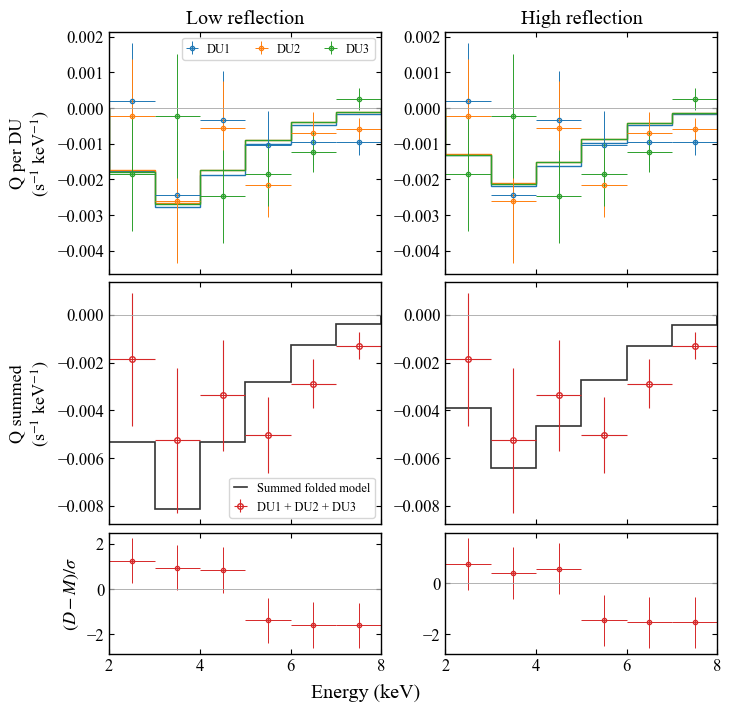

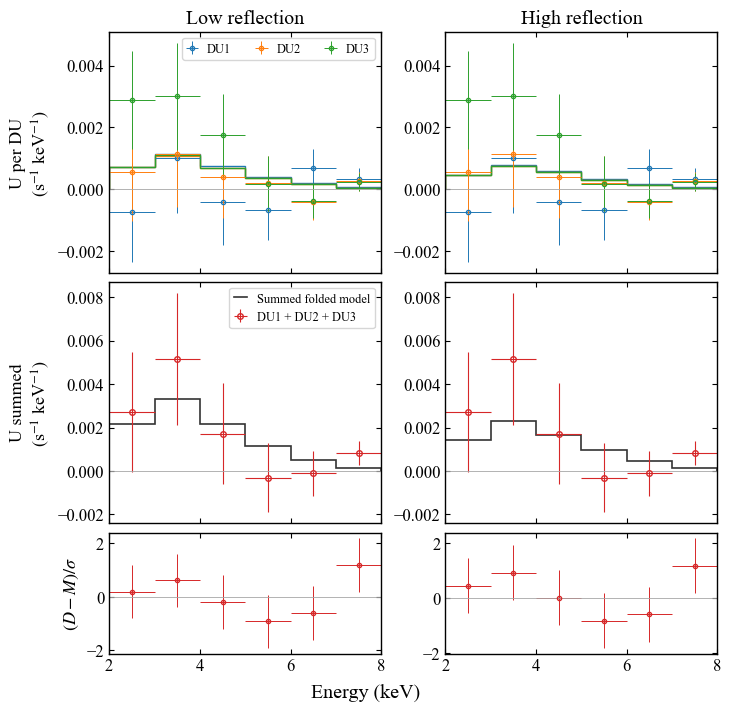

In [13]:
edges=np.arange(2.,9.);centres=(edges[:-1]+edges[1:])/2
for stokes in 'QU':
    fig,axs=plt.subplots(3,2,figsize=(7.2,7.0),sharex=True,
                         gridspec_kw={'height_ratios':[2,2,1]},layout='constrained')
    for col,branch in enumerate(['low','high']):
        r=merged[branch][stokes]
        for k,p in enumerate(r['parts']):
            axs[0,col].errorbar(centres,p['data'],xerr=.5,yerr=np.sqrt(np.diag(p['covariance'])),
                               fmt='o',mfc='none',ms=3,color=f'C{k}',lw=.7,label=f'DU{k+1}')
            axs[0,col].stairs(p['model'],edges,color=f'C{k}',lw=1)
        axs[1,col].errorbar(centres,r['data'],xerr=.5,yerr=r['error'],fmt='o',mfc='none',
                           ms=4,color='C3',lw=.8,label='DU1 + DU2 + DU3')
        axs[1,col].stairs(r['model'],edges,color='0.2',lw=1.2,label='Summed folded model')
        axs[2,col].errorbar(centres,r['residual_sigma'],xerr=.5,yerr=np.ones(6),
                           fmt='o',mfc='none',ms=3,color='C3',lw=.7)
        for ax in axs[:,col]:ax.axhline(0,color='0.65',lw=.6);ax.set_xlim(2,8)
        axs[0,col].set_title(branch.capitalize()+' reflection')
    axs[0,0].legend(fontsize=9,ncol=3,handlelength=.8)
    axs[1,0].legend(fontsize=9,handlelength=1)
    axs[0,0].set_ylabel(stokes+' per DU\n(s$^{-1}$ keV$^{-1}$)')
    axs[1,0].set_ylabel(stokes+' summed\n(s$^{-1}$ keV$^{-1}$)')
    axs[2,0].set_ylabel(r'$(D-M)/\sigma$')
    fig.supxlabel('Energy (keV)');plt.show()

## 10. Numerical audit and scope

We independently sum all saved native-bin squared residuals. The reported
degrees of freedom refer to all 1596 fitted points and 24/23 free parameters,
not to any merged or display-rebinned spectrum. Section 8 retains the original
fit points; Section 9 is display-only. This checks export integrity, not
uniqueness of the physical model.

To redo the full reduction one would additionally need the archived events,
CALDB and response files, mission software, and model dependencies listed in
the bindings. The available original extraction commands document our actual
choices; they are not automatically executed here. The original spacecraft
pipeline flags are not fully captured in this lightweight export, so we do not
claim that Run All reconstructs the archived cleaned events from telemetry.

In [14]:
rows=[]
for branch,d in fits.items():
    sums={s:0. for s in 'IQU'};n=0
    for r in d['native']:
        residual=(np.array(r['data'])-r['model'])/r['error']
        np.testing.assert_allclose(residual,r['residual_sigma'],atol=1e-10)
        sums[r['stokes']]+=float(residual@residual);n+=len(residual)
    np.testing.assert_allclose(sum(sums.values()),d['result']['chi2'],rtol=0,atol=1e-4)
    assert n==1596
    rows.append([branch,n,*sums.values(),sum(sums.values()),d['result']['dof']])
table(['Branch','Points','chi2 I','chi2 Q','chi2 U','Total chi2','dof'],rows)
print('All cached residual checks passed. No extraction, model recalculation or fitting was performed.')

Branch,Points,chi2 I,chi2 Q,chi2 U,Total chi2,dof
low,1596,699.1393130395479,419.57612114859944,451.1644186407296,1569.879852828877,1572
high,1596,699.0863451580452,416.9577922326993,451.53970534015536,1567.5838427309,1573


All cached residual checks passed. No extraction, model recalculation or fitting was performed.
